# HDI Classification: Preprocessing, Models and Evaluation

How we use the three splits:
- **Train (60%)**: all fitting and tuning, with 5-fold stratified CV and macro F1. The preprocessing is inside a
  `Pipeline`, so it is refitted in every fold.
- **Validation (20%)**: a second check on the tuned models, nothing is fitted on it.
- **Test (20%)**: used once, in section 8.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, make_scorer,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

warnings.filterwarnings('ignore', category=FutureWarning)

SEED = 42
FIG_DIR = '../outputs/figures'
TABLE_DIR = '../outputs/tables'
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(TABLE_DIR, exist_ok=True)

sns.set_theme(style='whitegrid')
pd.set_option('display.precision', 3)
pd.set_option('display.max_colwidth', 120)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(f'{FIG_DIR}/{name}.png', dpi=150, bbox_inches='tight')
    plt.show()

In [2]:
df = pd.read_csv('../data/hdi_dataset_2023.csv')

num_cols = ['gdp_growth', 'inflation', 'unemployment', 'infant_mortality', 'electricity_access',
            'internet_users', 'agriculture_share', 'industry_share', 'trade']
cat_cols = ['region', 'DominantSector']

# the six skewed features from the EDA where the log helped
skewed_cols = ['inflation', 'unemployment', 'infant_mortality', 'agriculture_share', 'industry_share', 'trade']
other_num_cols = ['gdp_growth', 'electricity_access', 'internet_users']

class_names = ['Low', 'Medium/High', 'Very High']

# hdi must not be in X (leakage). iso3, country and the *_year columns aren't predictors either
X = df[num_cols + cat_cols]
y = df['hdi_class']
print(X.shape)
print(list(X.columns))

(193, 11)
['gdp_growth', 'inflation', 'unemployment', 'infant_mortality', 'electricity_access', 'internet_users', 'agriculture_share', 'industry_share', 'trade', 'region', 'DominantSector']


## 1. Train / validation / test split (60 / 20 / 20, stratified, seed 42)

In [3]:
# 20% test first, then 25% of what's left for validation (so 60/20/20 overall)
X_trval, X_test, y_trval, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_trval, y_trval, test_size=0.25, stratify=y_trval, random_state=SEED)

counts = pd.DataFrame({
    'train': y_train.value_counts().sort_index(),
    'val': y_val.value_counts().sort_index(),
    'test': y_test.value_counts().sort_index(),
    'all': y.value_counts().sort_index(),
})
counts.index = class_names
percentages = (counts / counts.sum() * 100).round(1).add_suffix(' %')
counts.loc['Total'] = counts.sum()
display(pd.concat([counts, percentages], axis=1))

# save the split so we know which country ended up where
split = pd.Series('train', index=df.index)
split[X_val.index] = 'val'
split[X_test.index] = 'test'
df[['iso3', 'country', 'hdi_class']].assign(split=split).to_csv(f'{TABLE_DIR}/split_assignment.csv', index=False)

missing_regions = set(X['region']) - set(X_train['region'])
print('Regions not in the training set:', missing_regions if missing_regions else 'none')

,train,val,test,all,train %,val %,test %,all %
Low,16,5,5,26,13.9,12.8,12.8,13.5
Medium/High,55,19,19,93,47.8,48.7,48.7,48.2
Very High,44,15,15,74,38.3,38.5,38.5,38.3
Total,115,39,39,193,NaN,NaN,NaN,NaN


Regions not in the training set: none


The class proportions are the same in all three parts. Validation and test only have 5 Low countries each, so those
scores will be noisy. That's why we choose models using CV on the training set.

## 2. Preprocessing pipeline

| Columns | Steps |
|---|---|
| Skewed numerical (6) | signed log → impute → standardize |
| Other numerical (3) | impute → standardize |
| Categorical (region, DominantSector) | fill with "Missing" → one-hot encoding |

We use a "Missing" category because 4 of the 7 countries with no sector are Low, and filling them with "Services"
would hide that. Standardizing is for logistic regression and PCA (trees don't need it).

In [4]:
def signed_log(x):
    return np.sign(x) * np.log1p(np.abs(x))


def make_preprocessor(strategy='median', indicators=False, use_num=True, cat_features=cat_cols):
    parts = []

    if use_num:
        skewed_pipe = Pipeline([
            ('signed_log', FunctionTransformer(signed_log, feature_names_out='one-to-one')),
            ('impute', SimpleImputer(strategy=strategy, add_indicator=indicators)),
            ('scale', StandardScaler()),
        ])
        other_pipe = Pipeline([
            ('impute', SimpleImputer(strategy=strategy, add_indicator=indicators)),
            ('scale', StandardScaler()),
        ])
        parts.append(('log', skewed_pipe, skewed_cols))
        parts.append(('num', other_pipe, other_num_cols))

    if len(cat_features) > 0:
        cat_pipe = Pipeline([
            ('impute', SimpleImputer(strategy='constant', fill_value='Missing')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
        ])
        parts.append(('cat', cat_pipe, list(cat_features)))

    return ColumnTransformer(parts)


def clean_names(names):
    # sklearn gives names like 'log__missingindicator_trade', we want 'missing:trade'
    cleaned = []
    for name in names:
        name = name.split('__', 1)[1]
        name = name.replace('missingindicator_', 'missing:')
        cleaned.append(name)
    return cleaned


# quick check that it works
test_prep = make_preprocessor('median', indicators=True)
test_prep.fit(X_train)
print('Shape after preprocessing:', test_prep.transform(X_train).shape)
print(clean_names(test_prep.get_feature_names_out()))

Shape after preprocessing: (115, 27)
['inflation', 'unemployment', 'infant_mortality', 'agriculture_share', 'industry_share', 'trade', 'missing:inflation', 'missing:unemployment', 'missing:infant_mortality', 'missing:agriculture_share', 'missing:industry_share', 'missing:trade', 'gdp_growth', 'electricity_access', 'internet_users', 'missing:internet_users', 'region_East Asia & Pacific', 'region_Europe & Central Asia', 'region_Latin America & Caribbean', 'region_Middle East, North Africa, Afghanistan & Pakistan', 'region_North America', 'region_South Asia', 'region_Sub-Saharan Africa', 'DominantSector_Agriculture', 'DominantSector_Industry', 'DominantSector_Missing', 'DominantSector_Services']


## 3. Models and hyperparameters

A majority-class baseline, multinomial logistic regression, a decision tree and a random forest. The grids are small
because we only have 115 training countries. Class weights are tuned too because the classes are imbalanced.

In [5]:
def get_model(name):
    # a new model and the hyperparameters to try for it
    if name == 'Baseline':
        return DummyClassifier(strategy='most_frequent'), {}

    if name == 'Logistic Regression':
        model = LogisticRegression(max_iter=5000, random_state=SEED)
        grid = {'clf__C': [0.01, 0.1, 1, 10, 100],
                'clf__class_weight': [None, 'balanced']}
        return model, grid

    if name == 'Decision Tree':
        model = DecisionTreeClassifier(random_state=SEED)
        grid = {'clf__max_depth': [2, 3, 4, 6, None],
                'clf__min_samples_leaf': [1, 3, 5],
                'clf__class_weight': [None, 'balanced']}
        return model, grid

    if name == 'Random Forest':
        model = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=1)
        grid = {'clf__max_depth': [None, 5],
                'clf__min_samples_leaf': [1, 3],
                'clf__max_features': ['sqrt', 0.5],
                'clf__class_weight': [None, 'balanced']}
        return model, grid


all_models = ['Baseline', 'Logistic Regression', 'Decision Tree', 'Random Forest']
learners = ['Logistic Regression', 'Decision Tree', 'Random Forest']

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
macro_f1 = make_scorer(f1_score, average='macro', zero_division=0)


def tune_model(name, preprocessor, use_pca=False):
    # tune with CV on the training set only, then see how the best one does on validation
    model, grid = get_model(name)

    steps = [('prep', preprocessor)]
    if use_pca:
        steps.append(('pca', PCA(random_state=SEED)))
        grid['pca__n_components'] = [2, 3, 5, 0.90]
    steps.append(('clf', model))

    search = GridSearchCV(Pipeline(steps), grid, scoring=macro_f1, cv=cv, n_jobs=-1)
    search.fit(X_train, y_train)

    best = search.best_index_
    val_pred = search.predict(X_val)
    result = {
        'model': name,
        'cv_f1_mean': search.cv_results_['mean_test_score'][best],
        'cv_f1_std': search.cv_results_['std_test_score'][best],
        'val_f1': f1_score(y_val, val_pred, average='macro', zero_division=0),
        'val_bal_acc': balanced_accuracy_score(y_val, val_pred),
        'best_params': {key.split('__')[1]: value for key, value in search.best_params_.items()},
    }
    return result, search.best_estimator_


def add_cv_text(results):
    # so the tables show mean ± std in one column
    results['CV F1'] = [f'{m:.3f} ± {s:.3f}' for m, s in zip(results['cv_f1_mean'], results['cv_f1_std'])]
    return results

## 4. Imputation: median vs mean, with and without missingness indicators

We re-tune the three models for each option and keep the one with the best average CV macro F1.

In [6]:
imputation_options = {
    'median': ('median', False),
    'mean': ('mean', False),
    'median + indicators': ('median', True),
    'mean + indicators': ('mean', True),
}

rows = []
for option, (strategy, indicators) in imputation_options.items():
    for name in learners:
        result, _ = tune_model(name, make_preprocessor(strategy, indicators))
        result['imputation'] = option
        rows.append(result)

imp_results = add_cv_text(pd.DataFrame(rows))
imp_results.drop(columns='CV F1').to_csv(f'{TABLE_DIR}/imputation_comparison.csv', index=False)

option_order = list(imputation_options)
print('CV macro F1 (mean ± std):')
display(imp_results.pivot(index='imputation', columns='model', values='CV F1').loc[option_order])
print('Validation macro F1:')
display(imp_results.pivot(index='imputation', columns='model', values='val_f1').loc[option_order])

average = imp_results.groupby('imputation')[['cv_f1_mean', 'val_f1']].mean().loc[option_order]
average.columns = ['average CV F1 (3 models)', 'average val F1 (3 models)']
display(average)

best_imputation = average['average CV F1 (3 models)'].idxmax()
print('Chosen imputation:', best_imputation)

CV macro F1 (mean ± std):


model,Decision Tree,Logistic Regression,Random Forest
imputation,,,
median,0.848 ± 0.093,0.857 ± 0.061,0.909 ± 0.056
mean,0.848 ± 0.093,0.857 ± 0.061,0.917 ± 0.046
median + indicators,0.859 ± 0.075,0.869 ± 0.057,0.913 ± 0.091
mean + indicators,0.859 ± 0.075,0.876 ± 0.066,0.924 ± 0.056


Validation macro F1:


model,Decision Tree,Logistic Regression,Random Forest
imputation,,,
median,0.756,0.706,0.742
mean,0.756,0.706,0.742
median + indicators,0.717,0.803,0.742
mean + indicators,0.717,0.803,0.755


,average CV F1 (3 models),average val F1 (3 models)
imputation,,
median,0.871,0.735
mean,0.874,0.735
median + indicators,0.881,0.754
mean + indicators,0.886,0.759


Chosen imputation: mean + indicators


All four options are within 0.015 of each other, which is less than the spread between folds, so imputation doesn't
matter much here. We use mean + indicators for the rest of the notebook since it has the best average (0.886).

## 5. Comparing the models (all features, chosen imputation)

In [7]:
best_strategy, best_indicators = imputation_options[best_imputation]

rows = []
best_models = {}
for name in all_models:
    result, model = tune_model(name, make_preprocessor(best_strategy, best_indicators))
    rows.append(result)
    best_models[name] = model

model_results = add_cv_text(pd.DataFrame(rows))
model_results.drop(columns='CV F1').to_csv(f'{TABLE_DIR}/model_comparison_cv_val.csv', index=False)
display(model_results.set_index('model')[['CV F1', 'val_f1', 'val_bal_acc', 'best_params']])

# pick the final model by CV score, not by validation score
learner_results = model_results[model_results['model'] != 'Baseline']
final_model = learner_results.sort_values('cv_f1_mean', ascending=False).iloc[0]['model']
print('Final model (best CV macro F1):', final_model)

,CV F1,val_f1,val_bal_acc,best_params
model,,,,
Baseline,0.216 ± 0.000,0.218,0.333,{}
Logistic Regression,0.876 ± 0.066,0.803,0.770,"{'C': 10, 'class_weight': 'balanced'}"
Decision Tree,0.859 ± 0.075,0.717,0.681,"{'class_weight': None, 'max_depth': None, 'min_samples_leaf': 1}"
Random Forest,0.924 ± 0.056,0.755,0.716,"{'class_weight': None, 'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 1}"


Final model (best CV macro F1): Random Forest


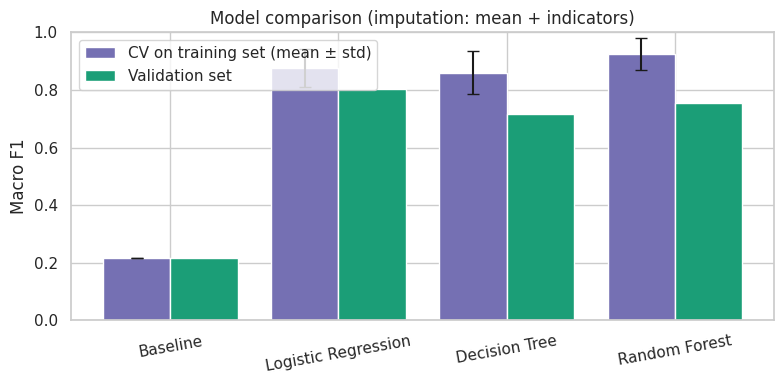

In [8]:
x = np.arange(len(model_results))
plt.figure(figsize=(8, 4))
plt.bar(x - 0.2, model_results['cv_f1_mean'], 0.4, yerr=model_results['cv_f1_std'], capsize=4,
        label='CV on training set (mean ± std)', color='#7570b3')
plt.bar(x + 0.2, model_results['val_f1'], 0.4, label='Validation set', color='#1b9e77')
plt.xticks(x, model_results['model'], rotation=10)
plt.ylabel('Macro F1')
plt.ylim(0, 1)
plt.title(f'Model comparison (imputation: {best_imputation})')
plt.legend(loc='upper left')
save_fig('model_comparison')

The random forest has the best CV score (0.924), so it is our final model. Validation ranks logistic regression first,
but with 39 countries the difference is within noise. Before testing, we check if PCA or fewer features would do better.

## 6. PCA

Number of features after preprocessing: 27
PC1 explains 23.1%, PC1-2 explain 39.3%, PC1-3 explain 47.7%
Components needed for 90% of the variance: 11


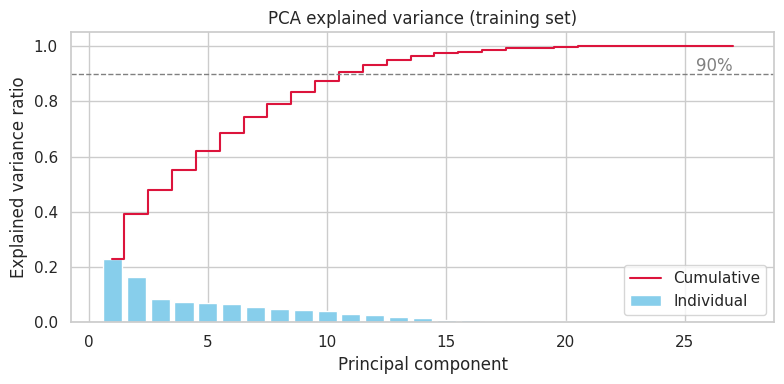

In [9]:
# PCA with all components, fitted on the training set only
prep = make_preprocessor(best_strategy, best_indicators)
prep.fit(X_train)
Z_train = prep.transform(X_train)
feature_names = clean_names(prep.get_feature_names_out())

pca = PCA(random_state=SEED)
pca.fit(Z_train)
explained = pca.explained_variance_ratio_
cumulative = np.cumsum(explained)
n_for_90 = int(np.argmax(cumulative >= 0.90) + 1)

print('Number of features after preprocessing:', Z_train.shape[1])
print(f'PC1 explains {explained[0]:.1%}, PC1-2 explain {cumulative[1]:.1%}, PC1-3 explain {cumulative[2]:.1%}')
print('Components needed for 90% of the variance:', n_for_90)

components = np.arange(1, len(explained) + 1)
plt.figure(figsize=(8, 4))
plt.bar(components, explained, color='skyblue', label='Individual')
plt.step(components, cumulative, where='mid', color='crimson', label='Cumulative')
plt.axhline(0.9, ls='--', color='grey', lw=1)
plt.text(len(explained), 0.91, '90%', ha='right', color='grey')
plt.xlabel('Principal component')
plt.ylabel('Explained variance ratio')
plt.title('PCA explained variance (training set)')
plt.legend()
save_fig('pca_explained_variance')

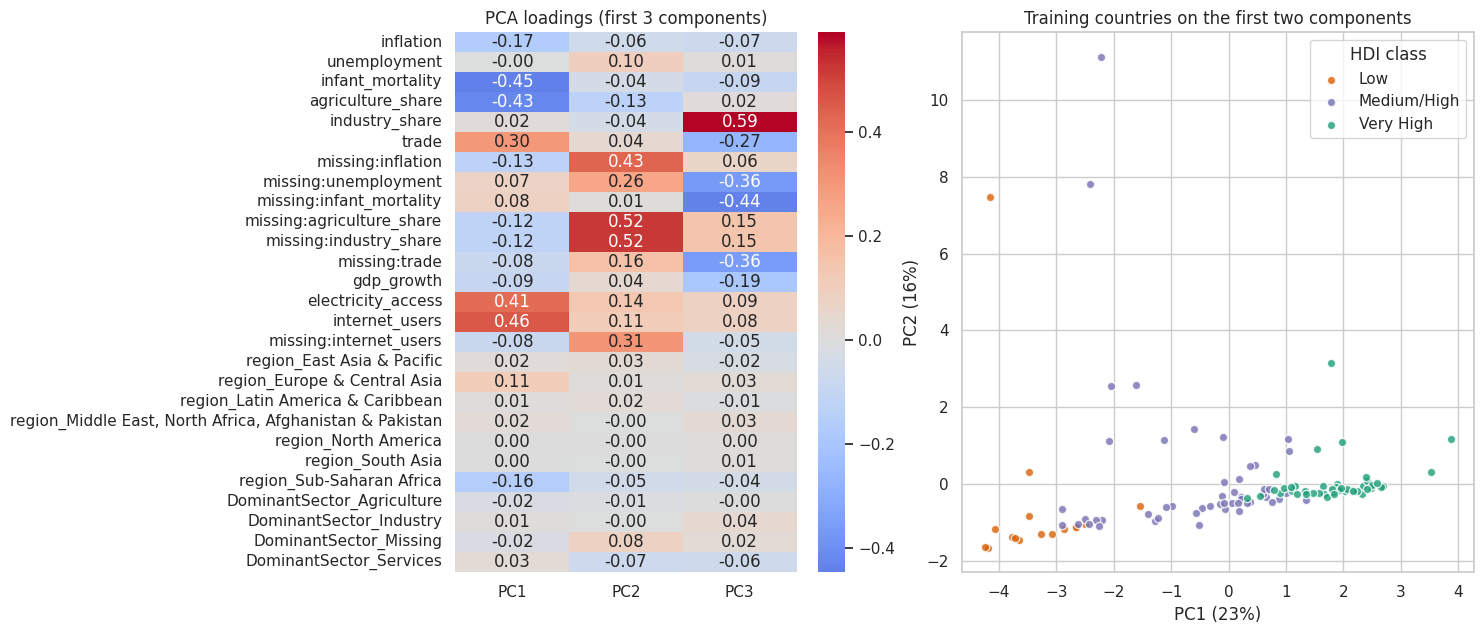

,PC1,PC2,PC3
internet_users,0.460,0.107,0.083
infant_mortality,-0.447,-0.039,-0.093
agriculture_share,-0.427,-0.129,0.018
electricity_access,0.411,0.137,0.086
trade,0.296,0.041,-0.272
inflation,-0.171,-0.057,-0.071
region_Sub-Saharan Africa,-0.158,-0.052,-0.042
missing:inflation,-0.129,0.431,0.063


In [10]:
loadings = pd.DataFrame(pca.components_[:3].T, index=feature_names, columns=['PC1', 'PC2', 'PC3'])
pcs = pca.transform(Z_train)

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), gridspec_kw={'width_ratios': [1, 1.2]})

sns.heatmap(loadings, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axes[0])
axes[0].set_title('PCA loadings (first 3 components)')

colors = ['#d95f02', '#7570b3', '#1b9e77']
for c in range(3):
    in_class = (y_train == c).values
    axes[1].scatter(pcs[in_class, 0], pcs[in_class, 1], label=class_names[c],
                    color=colors[c], alpha=0.8, edgecolor='white')
axes[1].set_xlabel(f'PC1 ({explained[0]:.0%})')
axes[1].set_ylabel(f'PC2 ({explained[1]:.0%})')
axes[1].set_title('Training countries on the first two components')
axes[1].legend(title='HDI class')
save_fig('pca_loadings_scatter')

# what matters most in PC1
loadings.reindex(loadings['PC1'].abs().sort_values(ascending=False).index).head(8)

In [11]:
# same models again but with PCA, the number of components is also tuned
rows = []
for name in learners:
    result, _ = tune_model(name, make_preprocessor(best_strategy, best_indicators), use_pca=True)
    result['pca'] = 'with PCA'
    rows.append(result)

with_pca = pd.DataFrame(rows)
without_pca = model_results[model_results['model'].isin(learners)].drop(columns='CV F1').assign(pca='without PCA')
pca_results = add_cv_text(pd.concat([without_pca, with_pca]))
pca_results.drop(columns='CV F1').to_csv(f'{TABLE_DIR}/pca_comparison.csv', index=False)

print('CV macro F1:')
display(pca_results.pivot(index='model', columns='pca', values='CV F1'))
print('Validation macro F1:')
display(pca_results.pivot(index='model', columns='pca', values='val_f1'))
print('Best settings with PCA:')
display(with_pca.set_index('model')[['best_params']])

CV macro F1:


pca,with PCA,without PCA
model,,
Decision Tree,0.868 ± 0.062,0.859 ± 0.075
Logistic Regression,0.877 ± 0.052,0.876 ± 0.066
Random Forest,0.856 ± 0.099,0.924 ± 0.056


Validation macro F1:


pca,with PCA,without PCA
model,,
Decision Tree,0.821,0.717
Logistic Regression,0.821,0.803
Random Forest,0.821,0.755


Best settings with PCA:


,best_params
model,
Logistic Regression,"{'C': 1, 'class_weight': None, 'n_components': 2}"
Decision Tree,"{'class_weight': None, 'max_depth': 4, 'min_samples_leaf': 1, 'n_components': 5}"
Random Forest,"{'class_weight': 'balanced', 'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 3, 'n_components': 3}"


PC1 is basically a development axis and the classes line up along it. Logistic regression does just as well with only 2
components, but the random forest gets worse (0.856 vs 0.924), so the final model doesn't use PCA.

## 7. Feature sets: numerical only vs categorical only vs combined

In [12]:
feature_sets = {
    'numerical only': dict(use_num=True, cat_features=[]),
    'categorical only': dict(use_num=False, cat_features=cat_cols),
    'combined (num + region + sector)': dict(use_num=True, cat_features=cat_cols),
    'num + region': dict(use_num=True, cat_features=['region']),
    'num + DominantSector': dict(use_num=True, cat_features=['DominantSector']),
}

rows = []
for set_name, options in feature_sets.items():
    for name in learners:
        result, _ = tune_model(name, make_preprocessor(best_strategy, best_indicators, **options))
        result['feature_set'] = set_name
        rows.append(result)

fs_results = add_cv_text(pd.DataFrame(rows))
fs_results.drop(columns='CV F1').to_csv(f'{TABLE_DIR}/feature_set_comparison.csv', index=False)

set_order = list(feature_sets)
print('CV macro F1:')
display(fs_results.pivot(index='feature_set', columns='model', values='CV F1').loc[set_order])
print('Validation macro F1:')
display(fs_results.pivot(index='feature_set', columns='model', values='val_f1').loc[set_order])

CV macro F1:


model,Decision Tree,Logistic Regression,Random Forest
feature_set,,,
numerical only,0.854 ± 0.098,0.839 ± 0.063,0.914 ± 0.068
categorical only,0.655 ± 0.107,0.639 ± 0.112,0.619 ± 0.099
combined (num + region + sector),0.859 ± 0.075,0.876 ± 0.066,0.924 ± 0.056
num + region,0.851 ± 0.087,0.876 ± 0.066,0.923 ± 0.053
num + DominantSector,0.854 ± 0.098,0.833 ± 0.073,0.914 ± 0.068


Validation macro F1:


model,Decision Tree,Logistic Regression,Random Forest
feature_set,,,
numerical only,0.756,0.737,0.722
categorical only,0.621,0.604,0.552
combined (num + region + sector),0.717,0.803,0.755
num + region,0.756,0.784,0.722
num + DominantSector,0.756,0.765,0.842


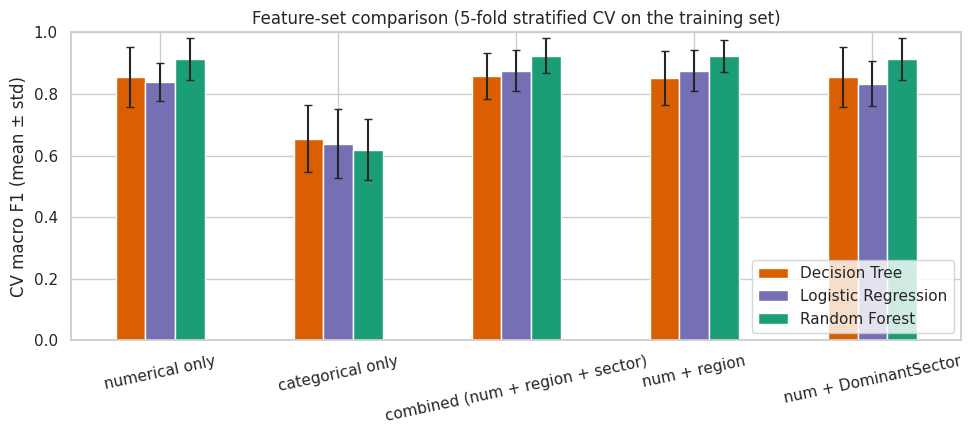

In [13]:
means = fs_results.pivot(index='feature_set', columns='model', values='cv_f1_mean').loc[set_order]
stds = fs_results.pivot(index='feature_set', columns='model', values='cv_f1_std').loc[set_order]

ax = means.plot(kind='bar', yerr=stds, capsize=3, figsize=(10, 4.5), color=['#d95f02', '#7570b3', '#1b9e77'], rot=12)
ax.set_ylabel('CV macro F1 (mean ± std)')
ax.set_xlabel('')
ax.set_ylim(0, 1)
ax.set_title('Feature-set comparison (5-fold stratified CV on the training set)')
ax.legend(loc='lower right')
save_fig('feature_set_comparison')

The numerical indicators carry most of the signal. Region mainly helps logistic regression (+0.037) and DominantSector
doesn't help. We keep all the features, since the combined set is the best or tied for best for all three models.

## 8. Final evaluation on the test set

All choices are fixed now, so we run the tuned models on the 39 test countries, once.

In [14]:
test_rows = []
test_preds = {}
for name, model in best_models.items():
    pred = model.predict(X_test)
    test_preds[name] = pred
    test_rows.append({
        'model': name,
        'final model': 'yes' if name == final_model else '',
        'accuracy': accuracy_score(y_test, pred),
        'balanced_accuracy': balanced_accuracy_score(y_test, pred),
        'macro_F1': f1_score(y_test, pred, average='macro', zero_division=0),
    })

test_results = pd.DataFrame(test_rows).set_index('model')
test_results.to_csv(f'{TABLE_DIR}/test_metrics.csv')
test_results

,final model,accuracy,balanced_accuracy,macro_F1
model,,,,
Baseline,,0.487,0.333,0.218
Logistic Regression,,0.821,0.730,0.726
Decision Tree,,0.795,0.605,0.565
Random Forest,yes,0.821,0.725,0.729


In [15]:
for name in learners:
    print(f'===== {name} =====')
    print(classification_report(y_test, test_preds[name], target_names=class_names, digits=3, zero_division=0))

===== Logistic Regression =====
              precision    recall  f1-score   support

         Low      0.400     0.400     0.400         5
 Medium/High      0.833     0.789     0.811        19
   Very High      0.938     1.000     0.968        15

    accuracy                          0.821        39
   macro avg      0.724     0.730     0.726        39
weighted avg      0.818     0.821     0.819        39

===== Decision Tree =====
              precision    recall  f1-score   support

         Low      0.000     0.000     0.000         5
 Medium/High      0.783     0.947     0.857        19
   Very High      0.812     0.867     0.839        15

    accuracy                          0.795        39
   macro avg      0.532     0.605     0.565        39
weighted avg      0.694     0.795     0.740        39

===== Random Forest =====
              precision    recall  f1-score   support

         Low      0.400     0.400     0.400         5
 Medium/High      0.800     0.842     0.821  

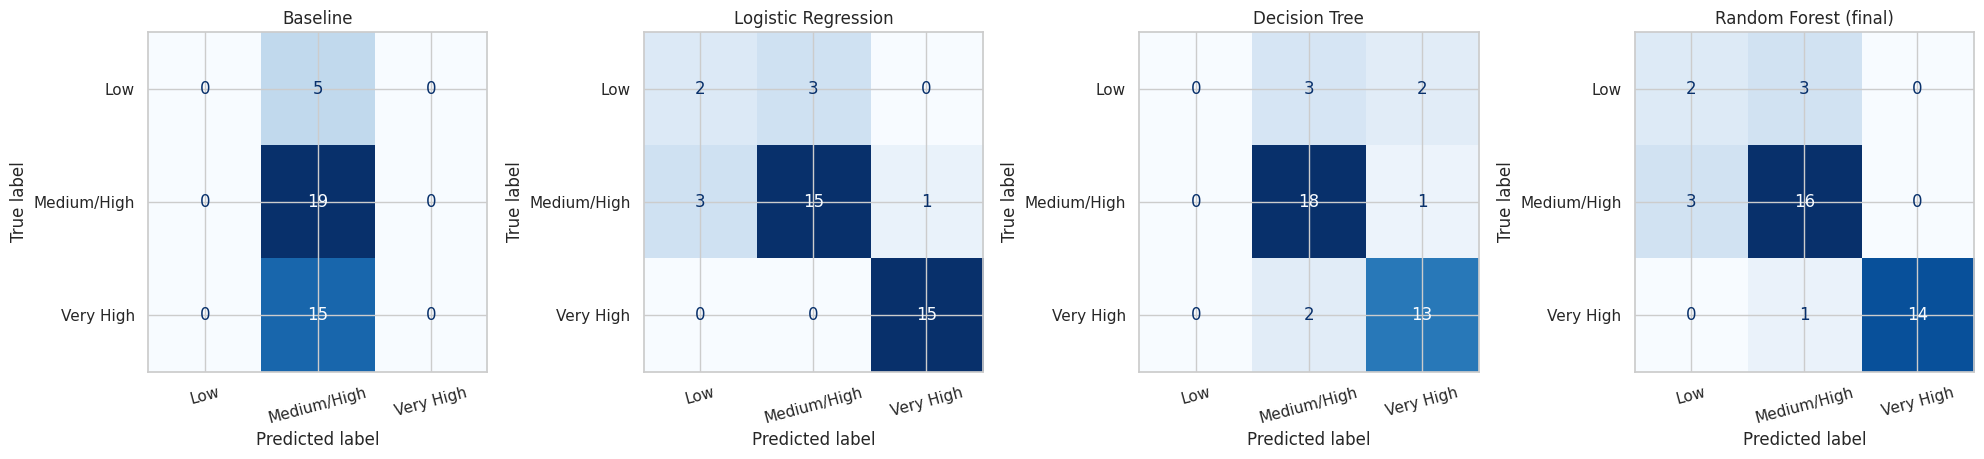

In [16]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.6))
for ax, name in zip(axes, all_models):
    cm = confusion_matrix(y_test, test_preds[name], labels=[0, 1, 2])
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, cmap='Blues', colorbar=False)
    title = name + ' (final)' if name == final_model else name
    ax.set_title(title)
    ax.tick_params(axis='x', rotation=15)
save_fig('confusion_matrices_test')

The random forest and logistic regression are basically tied (macro F1 0.729 and 0.726). Both get 2 of the 5 Low
countries right and only mix up neighbouring classes. The decision tree finds no Low country at all, which its accuracy
(0.795) hides. The drop from CV is mostly from the small Low class.

## 9. Interpreting the models

### 9a. Logistic regression coefficients

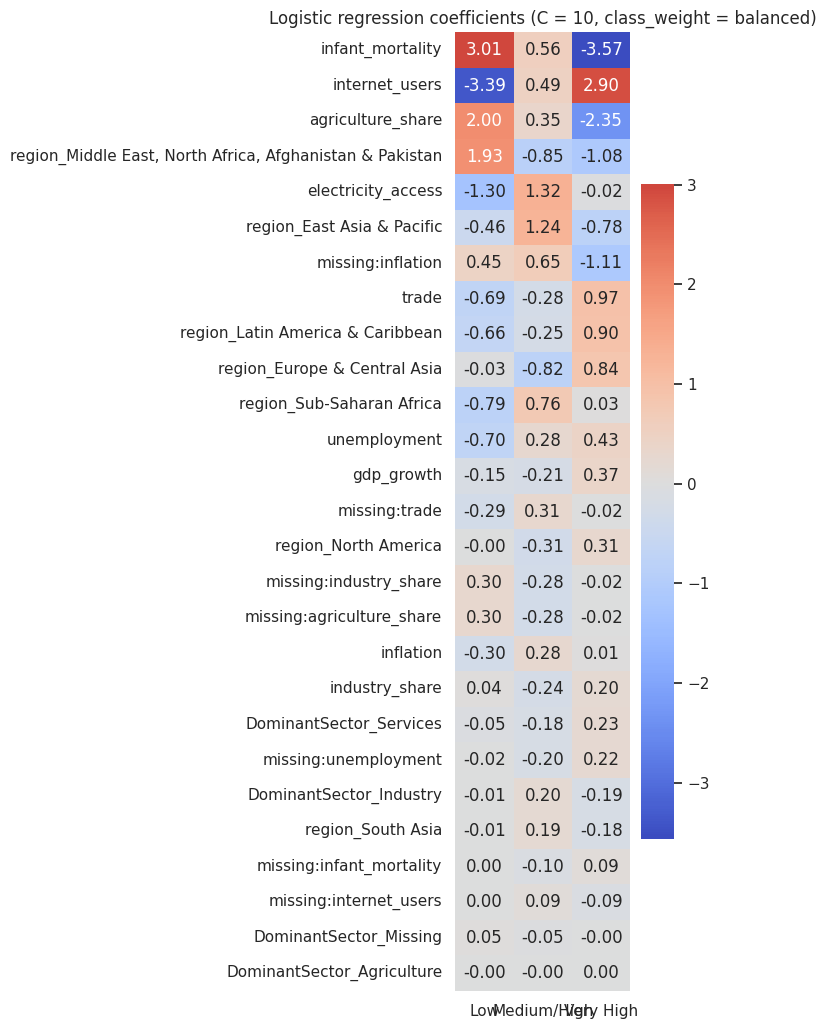

In [17]:
lr = best_models['Logistic Regression']
lr_names = clean_names(lr.named_steps['prep'].get_feature_names_out())
coef = pd.DataFrame(lr.named_steps['clf'].coef_.T, index=lr_names, columns=class_names)

# biggest coefficients on top (ignoring the sign)
order = coef.abs().max(axis=1).sort_values(ascending=False).index

plt.figure(figsize=(7, 0.35 * len(coef) + 1))
sns.heatmap(coef.loc[order], annot=True, fmt='.2f', cmap='coolwarm', center=0)
C = lr.named_steps['clf'].C
cw = lr.named_steps['clf'].class_weight
plt.title(f'Logistic regression coefficients (C = {C}, class_weight = {cw})')
save_fig('lr_coefficients')

Infant mortality, internet use and agriculture share have the biggest coefficients, same as in the EDA. These features
are correlated, so we only trust the direction and not the exact values. Next we see if the random forest agrees.

### 9b. Random forest permutation importance (test set, macro F1, 50 repeats)

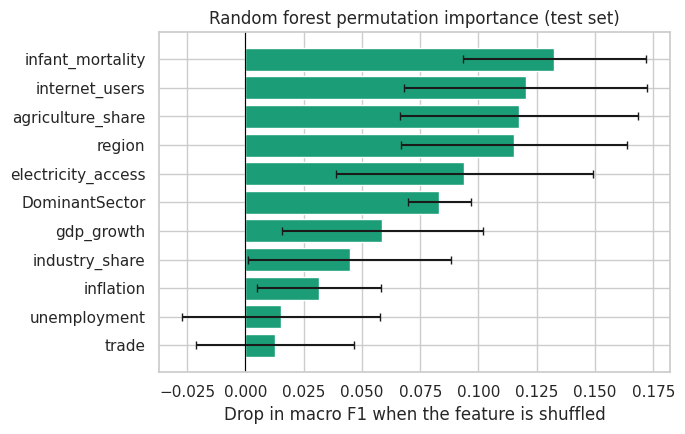

,mean_drop_in_macro_F1,std
infant_mortality,0.133,0.039
internet_users,0.120,0.052
agriculture_share,0.117,0.051
region,0.115,0.049
electricity_access,0.094,0.055
DominantSector,0.083,0.014
gdp_growth,0.059,0.043
industry_share,0.045,0.044
inflation,0.032,0.027
unemployment,0.015,0.043


In [18]:
rf = best_models['Random Forest']
perm = permutation_importance(rf, X_test, y_test, scoring=macro_f1, n_repeats=50, random_state=SEED, n_jobs=-1)

importance = pd.DataFrame({
    'mean_drop_in_macro_F1': perm.importances_mean,
    'std': perm.importances_std,
}, index=X_test.columns).sort_values('mean_drop_in_macro_F1')
importance.to_csv(f'{TABLE_DIR}/rf_permutation_importance.csv')

plt.figure(figsize=(7, 4.5))
plt.barh(importance.index, importance['mean_drop_in_macro_F1'], xerr=importance['std'], color='#1b9e77', capsize=3)
plt.axvline(0, color='black', lw=0.8)
plt.xlabel('Drop in macro F1 when the feature is shuffled')
plt.title('Random forest permutation importance (test set)')
save_fig('rf_permutation_importance')

importance.iloc[::-1]

It does, with region also near the top. DominantSector looks important, but in the test set only two countries aren't
"Services" and both are "Missing", so it only reflects those two. Section 7 is the better evidence.

### 9c. Decision tree (top levels)

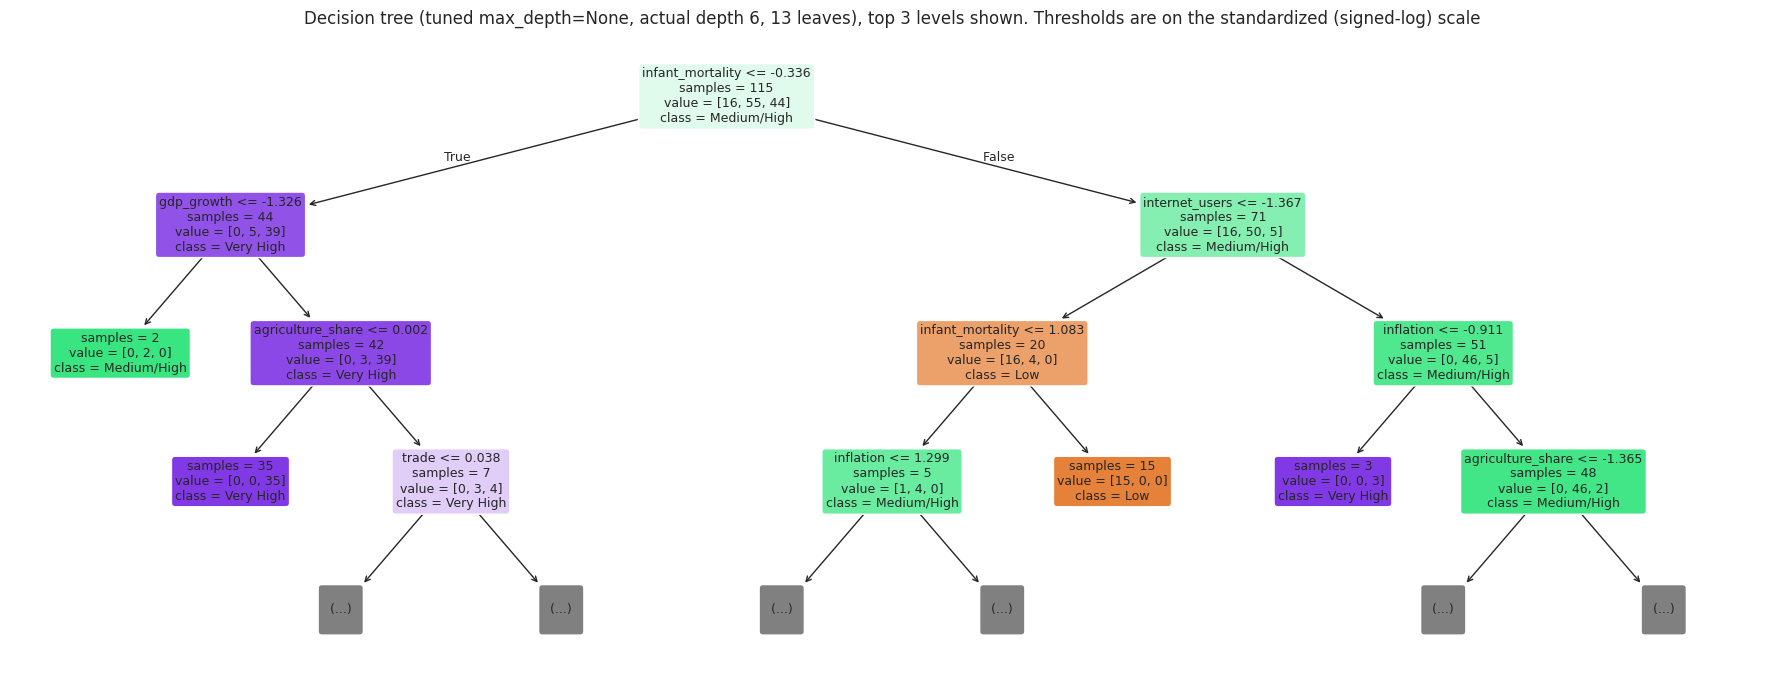

In [19]:
dt = best_models['Decision Tree']
tree = dt.named_steps['clf']
dt_names = clean_names(dt.named_steps['prep'].get_feature_names_out())

plt.figure(figsize=(18, 7))
plot_tree(tree, feature_names=dt_names, class_names=class_names, filled=True, rounded=True,
          max_depth=3, fontsize=9, impurity=False)
plt.title(f'Decision tree (tuned max_depth={tree.max_depth}, actual depth {tree.get_depth()}, '
          f'{tree.get_n_leaves()} leaves), top 3 levels shown. Thresholds are on the standardized (signed-log) scale')
save_fig('decision_tree')

The tree also starts with infant mortality, then internet use and agriculture share. It is fully grown, so it overfits
small groups of countries. Last, we look at which countries the models get wrong.

### 9d. Misclassified test countries

In [20]:
test_countries = df.loc[X_test.index, ['country', 'region', 'hdi']].copy()
test_countries['true'] = [class_names[c] for c in y_test]
for name in learners:
    test_countries[name] = [class_names[c] for c in test_preds[name]]

# how far each country is from the nearest cutoff (0.55 or 0.80)
dist_low = (test_countries['hdi'] - 0.550).abs()
dist_high = (test_countries['hdi'] - 0.800).abs()
test_countries['dist_to_threshold'] = np.minimum(dist_low, dist_high).round(3)

# only the countries that at least one model got wrong
wrong_somewhere = (test_countries[learners].ne(test_countries['true'], axis=0)).any(axis=1)
wrong = test_countries[wrong_somewhere].sort_values('hdi')
wrong.to_csv(f'{TABLE_DIR}/misclassified_test.csv', index=False)

print(f'{len(wrong)} of {len(test_countries)} test countries were misclassified by at least one model')
wrong

12 of 39 test countries were misclassified by at least one model


,country,region,hdi,true,Logistic Regression,Decision Tree,Random Forest,dist_to_threshold
114,Mali,Sub-Saharan Africa,0.419,Low,Low,Very High,Low,0.131
52,Eritrea,Sub-Saharan Africa,0.503,Low,Low,Medium/High,Low,0.047
149,Sudan,Sub-Saharan Africa,0.511,Low,Medium/High,Medium/High,Medium/High,0.039
45,Djibouti,"Middle East, North Africa, Afghanistan & Pakistan",0.513,Low,Medium/High,Very High,Medium/High,0.037
65,Gambia,Sub-Saharan Africa,0.524,Low,Medium/High,Medium/High,Medium/High,0.026
178,Tanzania (United Republic of),Sub-Saharan Africa,0.555,Medium/High,Low,Medium/High,Low,0.005
139,Papua New Guinea,East Asia & Pacific,0.576,Medium/High,Low,Medium/High,Low,0.026
179,Uganda,Sub-Saharan Africa,0.582,Medium/High,Low,Medium/High,Low,0.032
131,Nauru,East Asia & Pacific,0.703,Medium/High,Medium/High,Very High,Medium/High,0.097
111,Mexico,Latin America & Caribbean,0.789,Medium/High,Very High,Medium/High,Medium/High,0.011


Most of the mistakes are close to the 0.550 or 0.800 cutoff (Tanzania, Gambia, Mexico and others). Mali, Ireland and Nauru
are mistakes made only by the decision tree.

The test set is small, so all of this is uncertain, and the results are associations and not causes. The full
discussion and limitations are in the report.